In [ ]:
# 1. Setup
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/tinyml'
!unzip -q -o {OUT}/data.zip -d /content/
DATA = '/content/data'

import os, glob, json, shutil
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras

CLASSES = ["pad_A", "pad_B", "pad_C", "pad_D", "pad_E", "no_target"]  # same order as v1!
IMG, ALPHA, BATCH, SEED = 128, 0.35, 32, 42
FREEZE_BN = True   # keep BatchNorm layers frozen during fine-tuning (CV and final run)
tf.keras.utils.set_random_seed(SEED)

# One timestamp per run: final model -> final/<RUN>/, validation run -> val/<RUN>/ (earlier runs stay untouched)
RUN = datetime.now(ZoneInfo('Europe/Stockholm')).strftime('%Y-%m-%d_%H%M')
FINAL, n = f'{OUT}/final/{RUN}', 2
while os.path.exists(FINAL):            # same minute twice -> _2, _3, ...
    FINAL, n = f'{OUT}/final/{RUN}_{n}', n + 1
RUN = os.path.basename(FINAL)
VAL_DIR = f'{OUT}/val/{RUN}'
os.makedirs(FINAL); os.makedirs(VAL_DIR, exist_ok=True)
print('final ->', FINAL, '\nval   ->', VAL_DIR)

def savefig(name, folder=None):
    """Save the current figure as <folder>/<name>.png (default folder: FINAL). Call before plt.show()."""
    plt.savefig(f'{folder or FINAL}/{name}.png', dpi=150, bbox_inches='tight')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
final -> /content/drive/MyDrive/tinyml/final/2026-10-25_1311 
val   -> /content/drive/MyDrive/tinyml/val/2026-10-25_1311


In [ ]:
# 2. Index all images (uses log.csv; falls back to file names if a day has no log)
rows = []
for day_dir in sorted(glob.glob(f'{DATA}/day_*')):
    day = day_dir.rsplit('_', 1)[-1]
    log = os.path.join(day_dir, 'log.csv')
    if os.path.exists(log):
        d = pd.read_csv(log, dtype={'session': str})
        d['path'] = day_dir + '/' + d['file']
    else:
        d = pd.DataFrame({'path': glob.glob(f'{day_dir}/*/*.jpg')})
        d['class'] = d.path.str.split('/').str[-2]
        d['session'] = d.path.str.split('/').str[-1].str.rsplit('_', n=1).str[0]
    d['day'] = day
    rows.append(d[['path', 'class', 'day', 'session']])
df = pd.concat(rows, ignore_index=True)
df = df[df.path.map(os.path.exists) & df['class'].isin(CLASSES)]
df['session'] = df.day + '_' + df.session.astype(str)
TEST_DAYS = ['D', 'E']  # held-out test days: never train on them
df = df[~df.day.isin(TEST_DAYS)]
assert not df.day.isin(TEST_DAYS).any()
print(df.groupby(['class', 'day']).size().unstack(fill_value=0))

day         A    C
class             
no_target  90  120
pad_A      90   90
pad_B      90   90
pad_C      90   90
pad_D      90   90
pad_E      90   90


In [ ]:
# 3. FINAL: every session goes into training (no holdout)
df['split'] = 'train'
print(df.groupby(['class', 'day']).size().unstack(fill_value=0))

day         A    C
class             
no_target  90  120
pad_A      90   90
pad_B      90   90
pad_C      90   90
pad_D      90   90
pad_E      90   90


In [ ]:
# 4. Datasets
def load(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.image.resize(img, (IMG, IMG), antialias=True), label  # squash, same as the Pi

def make_ds(d, train=False):
    paths = np.array(d['path'].tolist())
    labels = np.array([CLASSES.index(c) for c in d['class']], dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if train:
        ds = ds.shuffle(len(d), seed=SEED)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

tr = df
va = df.sample(64, random_state=SEED)  # only so the code runs; these images are also in training
train_ds, val_ds = make_ds(tr, True), make_ds(va)


train images per epoch: 1320 | extra tile negatives: 210


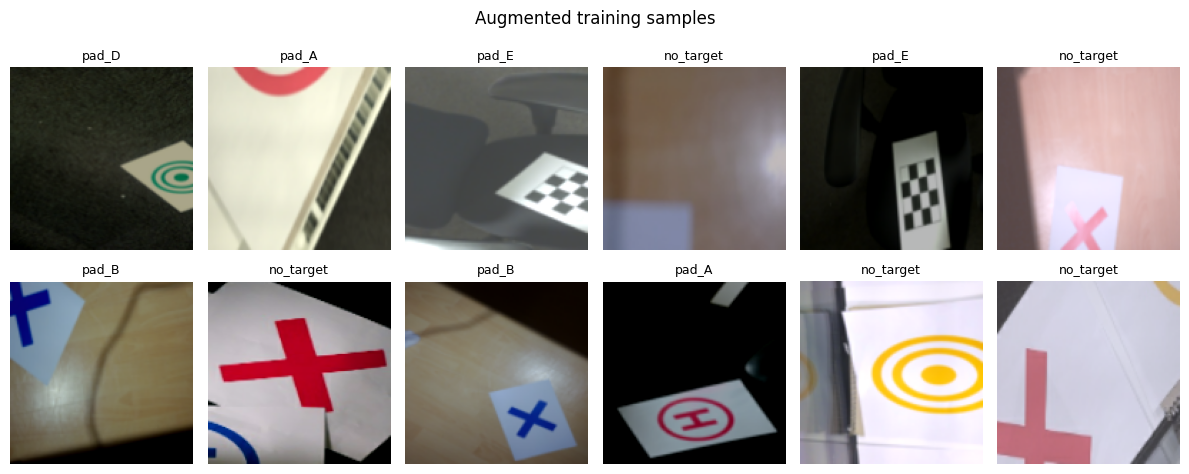

In [ ]:
# 5. Augmentation (tf.image, in the data pipeline) + model
def aug_one(img, label):
    img = tf.image.rot90(img, tf.random.uniform([], 0, 4, tf.int32))      # 0/90/180/270 deg
    img = tf.image.random_flip_left_right(img)
    size = tf.cast(tf.random.uniform([], 0.7, 1.0) * IMG, tf.int32)        # random zoom-in / shift
    img = tf.image.resize(tf.image.random_crop(img, [size, size, 3]), (IMG, IMG))
    img = tf.image.random_brightness(img, 0.25 * 255)
    img = tf.image.random_contrast(img, 0.75, 1.25)
    img = img * tf.random.uniform([3], 0.9, 1.1)                           # warm/cool light (per-channel gain)
    img = tf.clip_by_value(img, 0, 255) / 255.0                            # saturation/hue need 0..1
    img = tf.image.random_saturation(img, 0.7, 1.3)
    img = tf.image.random_hue(img, 0.03)                                   # small: colour is part of pad identity
    return tf.clip_by_value(img * 255.0, 0, 255), label

NT = CLASSES.index('no_target')

def tile_negative(path):
    """Random half-frame crop of a no_target image = what a pipeline tile sees."""
    img = tf.image.decode_jpeg(tf.io.read_file(path), channels=3)
    h, w = tf.shape(img)[0], tf.shape(img)[1]
    crop = tf.image.random_crop(img, [h // 2, w // 2, 3])
    return tf.image.resize(crop, (IMG, IMG)), tf.constant(NT, tf.int32)

tf.keras.backend.clear_session()
preprocess = keras.layers.Rescaling(1 / 127.5, offset=-1, name='preprocess')  # = mobilenet_v2.preprocess_input
base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), alpha=ALPHA,
                                      include_top=False, weights='imagenet')
base.trainable = False
gap  = keras.layers.GlobalAveragePooling2D()
drop = keras.layers.Dropout(0.3)
head = keras.layers.Dense(len(CLASSES), activation='softmax', name='probs')

inp = keras.Input((IMG, IMG, 3))
train_model = keras.Model(inp, head(drop(gap(base(preprocess(inp), training=False)))))

img  = keras.Input((IMG, IMG, 3), name='image')
feat = base(preprocess(img), training=False)
infer_model = keras.Model(img, [head(gap(feat)), feat])  # 2 outputs: probs + feature map (CAM)

neg_paths = tr.loc[tr['class'] == 'no_target', 'path'].tolist()
full_ds = (tf.data.Dataset.from_tensor_slices(
               (np.array(tr['path'].tolist()), np.array([CLASSES.index(c) for c in tr['class']], np.int32)))
           .map(load, num_parallel_calls=tf.data.AUTOTUNE))
tile_ds = (tf.data.Dataset.from_tensor_slices(np.array(neg_paths))
           .map(tile_negative, num_parallel_calls=tf.data.AUTOTUNE))
train_ds_aug = (full_ds.concatenate(tile_ds)
                .shuffle(len(tr) + len(neg_paths), seed=SEED)
                .map(aug_one, num_parallel_calls=tf.data.AUTOTUNE)
                .batch(BATCH).prefetch(tf.data.AUTOTUNE))
print("train images per epoch:", len(tr) + len(neg_paths), "| extra tile negatives:", len(neg_paths))

# Sanity check: what the model sees during training (12 augmented samples, incl. tile negatives)
xa, ya = next(iter(train_ds_aug))
plt.figure(figsize=(12, 5))
for i in range(12):
    plt.subplot(2, 6, i + 1); plt.imshow(xa[i].numpy().astype('uint8')); plt.title(CLASSES[ya[i]], fontsize=9); plt.axis('off')
plt.suptitle('Augmented training samples'); plt.tight_layout()
savefig('aug_samples'); savefig('aug_samples', VAL_DIR); plt.show()

In [ ]:
# 5b. VALIDATION: K-fold session-grouped cross-validation on the training days
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, f1_score
import gc

AUTO = tf.data.AUTOTUNE
K = 5
S1_EPOCHS, S2_EPOCHS, S2_LAYERS = 12, 8, 30   # identical to the final run

def labels_of(d):
    return np.array([CLASSES.index(c) for c in d['class']], np.int32)

def aug_train_ds(d):
    """Same recipe as the final run: augmentation + tile negatives (from this fold's train part only)."""
    full = (tf.data.Dataset.from_tensor_slices((np.array(d.path.tolist()), labels_of(d)))
            .map(load, num_parallel_calls=AUTO))
    negs = np.array(d.loc[d['class'] == 'no_target', 'path'].tolist())
    tiles = tf.data.Dataset.from_tensor_slices(negs).map(tile_negative, num_parallel_calls=AUTO)
    return (full.concatenate(tiles).shuffle(len(d) + len(negs), seed=SEED)
            .map(aug_one, num_parallel_calls=AUTO).batch(BATCH).prefetch(AUTO))

def build_model():
    """Same architecture as cell 5, fresh ImageNet weights."""
    b = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), alpha=ALPHA,
                                       include_top=False, weights='imagenet')
    b.trainable = False
    i = keras.Input((IMG, IMG, 3))
    x = keras.layers.Rescaling(1 / 127.5, offset=-1)(i)
    x = keras.layers.GlobalAveragePooling2D()(b(x, training=False))
    o = keras.layers.Dense(len(CLASSES), activation='softmax')(keras.layers.Dropout(0.3)(x))
    return keras.Model(i, o), b

# --- Folds: each session is in val exactly once
sgkf = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=SEED)
folds = list(sgkf.split(df, df['class'], groups=df['session']))
fold_of = np.zeros(len(df), int)
for k, (_, va_idx) in enumerate(folds, 1):
    fold_of[va_idx] = k
assert (fold_of > 0).all()
dff = df.assign(fold=fold_of)
split_tbl = dff.groupby(['class', 'fold']).size().unstack(fill_value=0).add_prefix('val_imgs_fold')
split_tbl['sessions'] = df.groupby('class').session.nunique()
print('Validation images per class and fold:'); print(split_tbl)
split_tbl.to_csv(f'{VAL_DIR}/folds.csv')
dff[['path', 'class', 'day', 'session', 'fold']].to_csv(f'{VAL_DIR}/fold_assignment.csv', index=False)

# --- Train + evaluate one model per fold
loss = 'sparse_categorical_crossentropy'
hists, oof, fold_rows = [], [], []
for k, (tr_idx, va_idx) in enumerate(folds, 1):
    print(f'\n===== fold {k}/{K} =====')
    v_tr, v_va = df.iloc[tr_idx], df.iloc[va_idx].copy()
    assert not set(v_tr.session) & set(v_va.session), 'session leakage'
    tf.keras.utils.set_random_seed(SEED + k)
    vmodel, vbase = build_model()
    vtrain_ds, vval_ds = aug_train_ds(v_tr), make_ds(v_va)   # val: clean full frames, no augmentation

    vmodel.compile(keras.optimizers.Adam(1e-3), loss=loss, metrics=['accuracy'])
    h1 = vmodel.fit(vtrain_ds, validation_data=vval_ds, epochs=S1_EPOCHS, verbose=2)
    vbase.trainable = True
    for layer in vbase.layers[:-S2_LAYERS]:
        layer.trainable = False
    if FREEZE_BN:
        for layer in vbase.layers:
            if isinstance(layer, keras.layers.BatchNormalization):
                layer.trainable = False
    vmodel.compile(keras.optimizers.Adam(1e-5), loss=loss, metrics=['accuracy'])
    h2 = vmodel.fit(vtrain_ds, validation_data=vval_ds, epochs=S2_EPOCHS, verbose=2)

    h = pd.concat([pd.DataFrame(h1.history).assign(stage=1),
                   pd.DataFrame(h2.history).assign(stage=2)], ignore_index=True)
    h['epoch'], h['fold'] = np.arange(1, len(h) + 1), k
    hists.append(h)

    # Out-of-fold predictions
    p = vmodel.predict(vval_ds, verbose=0)
    y, yhat = labels_of(v_va), p.argmax(1)
    v_va = v_va.assign(fold=k, pred=[CLASSES[i] for i in yhat], conf=p.max(1), ok=yhat == y)
    v_va = v_va.join(pd.DataFrame(p, columns=[f'p_{c}' for c in CLASSES], index=v_va.index))
    oof.append(v_va)

    # Tile-level check: half-frame crops of this fold's val no_target images
    tile_rate = np.nan
    negs = np.array(v_va.loc[v_va['class'] == 'no_target', 'path'].tolist())
    if len(negs):
        pt = vmodel.predict(tf.data.Dataset.from_tensor_slices(negs).map(tile_negative).batch(BATCH), verbose=0)
        tile_rate = float((pt.argmax(1) == NT).mean())

    row = {'fold': k, 'n_val': len(v_va), 'n_val_sessions': v_va.session.nunique(),
           'acc': float((yhat == y).mean()),
           'macro_f1': float(f1_score(y, yhat, labels=np.unique(y), average='macro', zero_division=0)),
           'val_loss_end_stage1': float(h.val_loss[S1_EPOCHS - 1]),
           'val_loss_final': float(h.val_loss.iloc[-1]),
           'best_val_loss_epoch': int(h.epoch[h.val_loss.idxmin()]),
           'tile_no_target_rate': tile_rate}
    for i, c in enumerate(CLASSES):          # NaN when this fold has no val images of class c
        m = y == i
        row[f'recall_{c}'] = float((yhat[m] == i).mean()) if m.any() else np.nan
    fold_rows.append(row)
    print({kk: (round(v, 3) if isinstance(v, float) else v) for kk, v in row.items()})

    del vmodel, vbase, vtrain_ds, vval_ds; gc.collect()

hist = pd.concat(hists, ignore_index=True); hist.to_csv(f'{VAL_DIR}/history_all_folds.csv', index=False)
oof = pd.concat(oof).loc[df.index]           # back to df order; every image exactly once
oof.drop(columns=['split'], errors='ignore').to_csv(f'{VAL_DIR}/oof_predictions.csv', index=False)
folds_df = pd.DataFrame(fold_rows).set_index('fold'); folds_df.to_csv(f'{VAL_DIR}/per_fold_metrics.csv')
tf.keras.utils.set_random_seed(SEED)         # final run below is unaffected

Validation images per class and fold:
fold       val_imgs_fold1  val_imgs_fold2  val_imgs_fold3  val_imgs_fold4  \
class                                                                       
no_target              90              90               0              30   
pad_A                  30              60              60               0   
pad_B                  30              30              60              30   
pad_C                  30              30              30              60   
pad_D                  60               0              30              60   
pad_E                   0              30              30              30   

fold       val_imgs_fold5  sessions  
class                                
no_target               0         7  
pad_A                  30         6  
pad_B                  30         6  
pad_C                  30         6  
pad_D                  30         6  
pad_E                  90         6  

===== fold 1/5 =====
Epoch 1/12
31/31 - 

{'fold': 1, 'n_val': 240, 'n_val_sessions': 8, 'acc': 0.779, 'macro_f1': 0.792, 'val_loss_end_stage1': 0.793, 'val_loss_final': 0.664, 'best_val_loss_epoch': 19, 'tile_no_target_rate': 0.9, 'recall_pad_A': 1.0, 'recall_pad_B': 0.933, 'recall_pad_C': 1.0, 'recall_pad_D': 0.6, 'recall_pad_E': nan, 'recall_no_target': 0.7}

===== fold 2/5 =====
Epoch 1/12
31/31 - 21s - 681ms/step - accuracy: 0.4343 - loss: 1.4791 - val_accuracy: 0.3250 - val_loss: 1.7021
Epoch 2/12
31/31 - 14s - 456ms/step - accuracy: 0.7434 - loss: 0.7611 - val_accuracy: 0.3750 - val_loss: 1.5032
Epoch 3/12
31/31 - 15s - 497ms/step - accuracy: 0.8040 - loss: 0.5799 - val_accuracy: 0.3750 - val_loss: 1.5395
Epoch 4/12
31/31 - 15s - 498ms/step - accuracy: 0.8566 - loss: 0.4703 - val_accuracy: 0.4917 - val_loss: 1.3721
Epoch 5/12
31/31 - 15s - 482ms/step - accuracy: 0.8455 - loss: 0.4354 - val_accuracy: 0.5125 - val_loss: 1.3031
Epoch 6/12
31/31 - 15s - 471ms/step - accuracy: 0.8657 - loss: 0.4088 - val_accuracy: 0.5458 - v

Per fold:
      n_val  n_val_sessions    acc  macro_f1  val_loss_end_stage1  \
fold                                                                
1       240               8  0.779     0.792                0.793   
2       240               8  0.704     0.688                1.100   
3       210               7  0.819     0.872                0.508   
4       210               7  0.652     0.715                1.103   
5       210               7  0.743     0.733                0.701   

      val_loss_final  best_val_loss_epoch  tile_no_target_rate  recall_pad_A  \
fold                                                                           
1              0.664                   19                0.900         1.000   
2              1.012                   20                0.956         0.617   
3              0.585                   12                  NaN         0.850   
4              1.107                    6                1.000           NaN   
5              0.725      

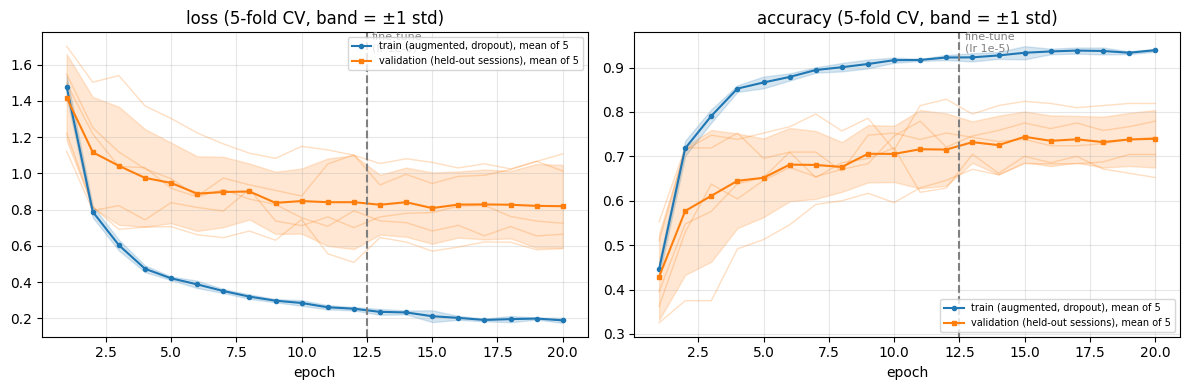

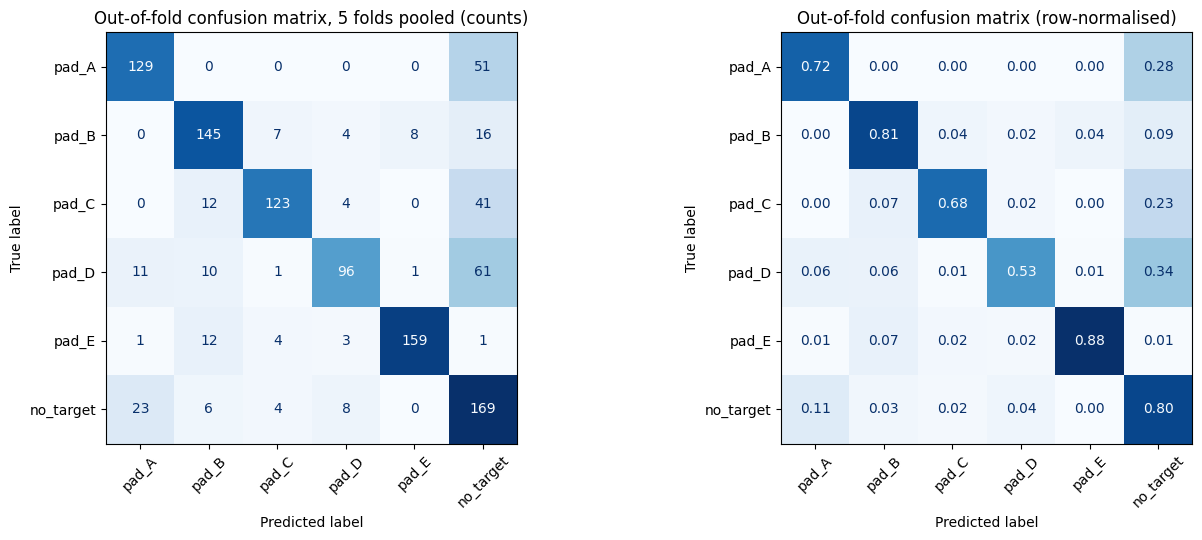

Pooled out-of-fold report:
              precision    recall  f1-score   support

       pad_A      0.787     0.717     0.750       180
       pad_B      0.784     0.806     0.795       180
       pad_C      0.885     0.683     0.771       180
       pad_D      0.835     0.533     0.651       180
       pad_E      0.946     0.883     0.914       180
   no_target      0.499     0.805     0.616       210

    accuracy                          0.740      1110
   macro avg      0.789     0.738     0.749      1110
weighted avg      0.781     0.740     0.746      1110



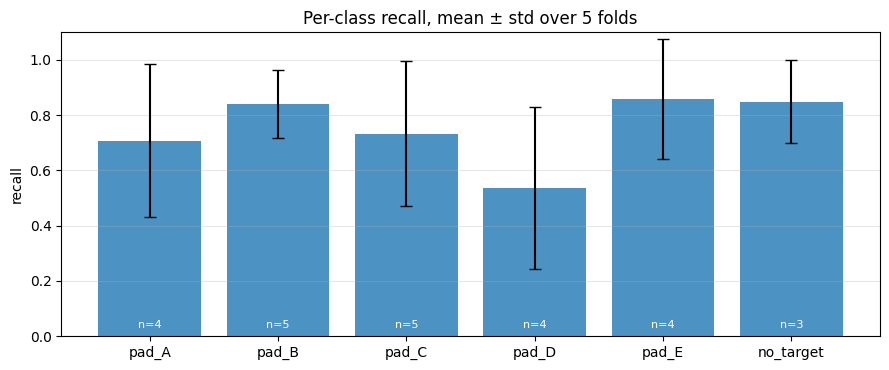

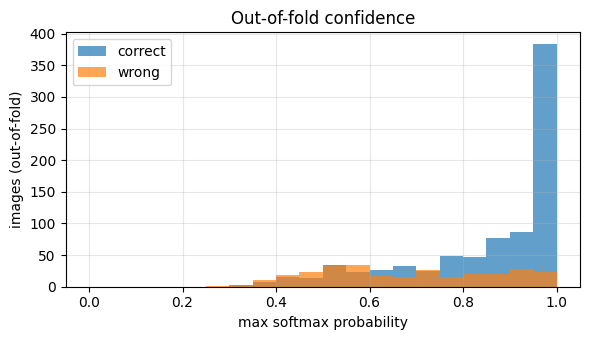

289 out-of-fold errors; by true class: {'pad_D': 84, 'pad_C': 57, 'pad_A': 51, 'no_target': 41, 'pad_B': 35, 'pad_E': 21}


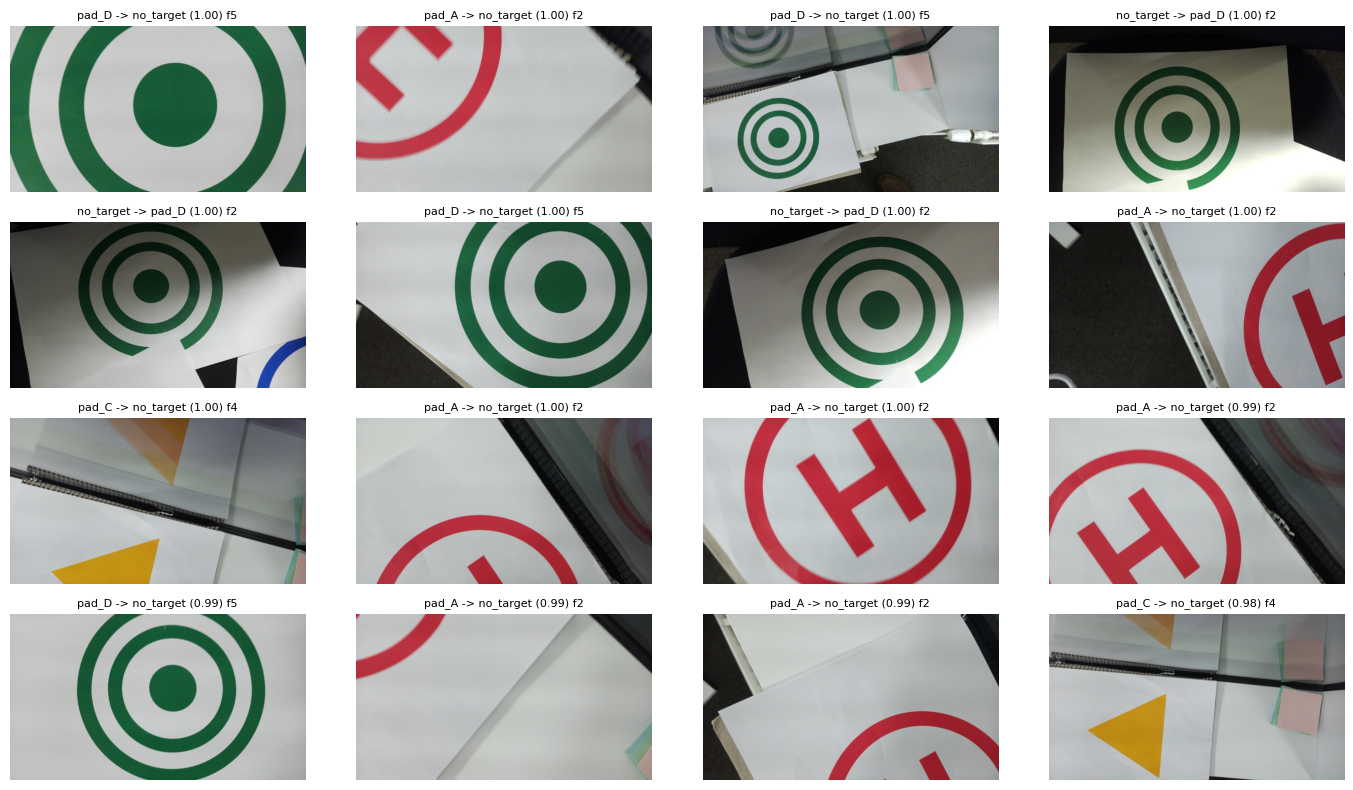

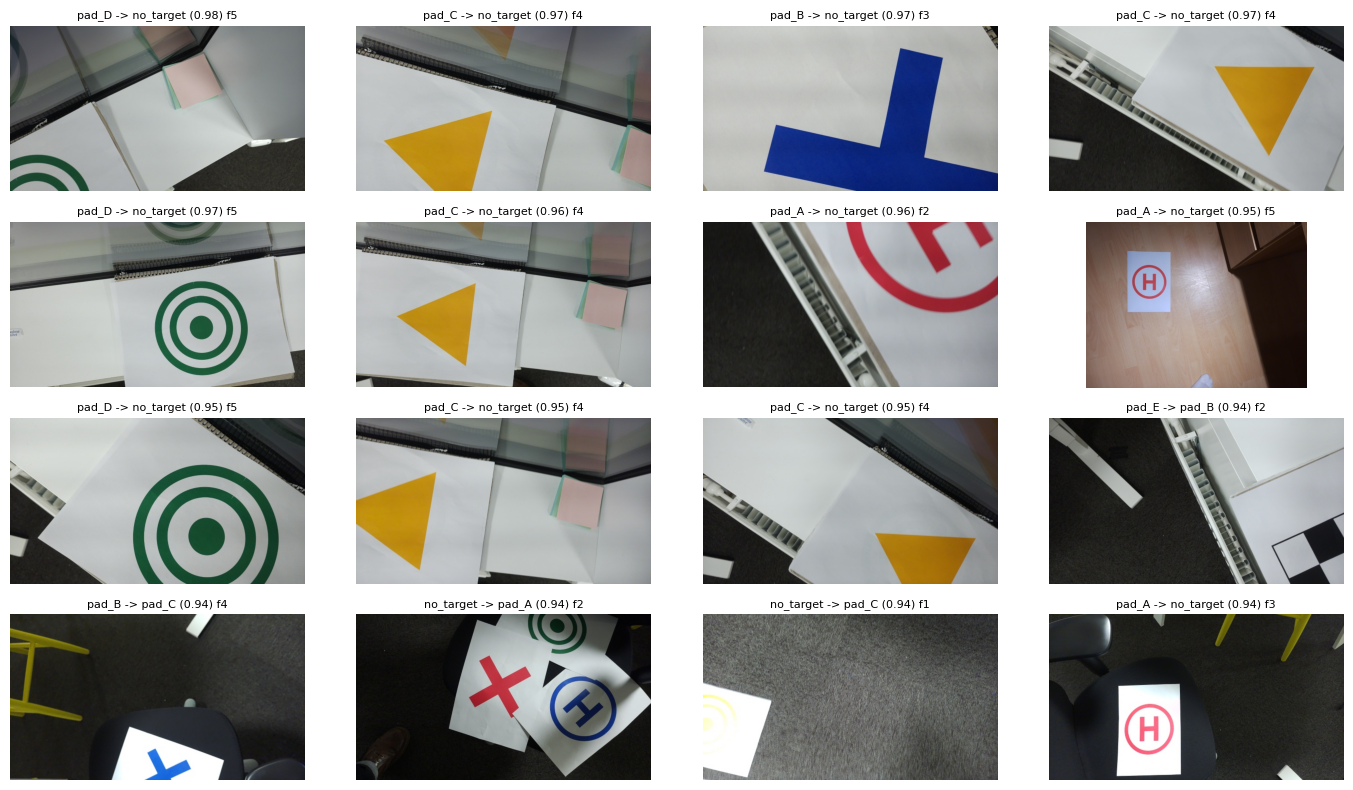

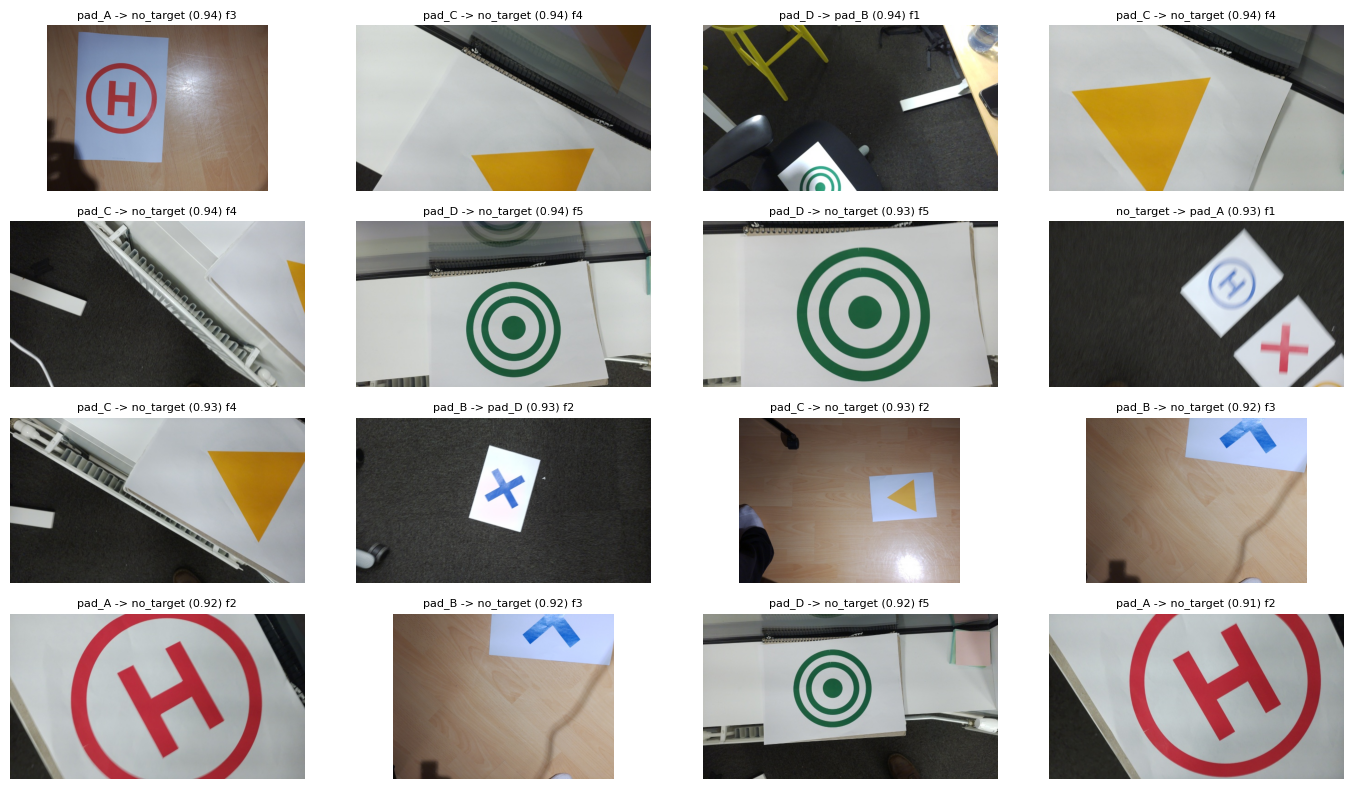


Accuracy 0.740 ± 0.065 | macro-F1 0.760 ± 0.073 | tile no_target 0.952 ± 0.050
Validation outputs: ['aug_samples.png', 'cv_classification_report.txt', 'cv_confidence_hist.png', 'cv_confusion_matrix.png', 'cv_curves.png', 'cv_errors_1.png', 'cv_errors_2.png', 'cv_errors_3.png', 'cv_per_class_recall.png', 'cv_summary.csv', 'fold_assignment.csv', 'folds.csv', 'history_all_folds.csv', 'oof_predictions.csv', 'per_fold_metrics.csv', 'summary.json']


In [ ]:
# 5c. Cross-validation results: mean ± std + plots -> VAL_DIR
recall_cols = [f'recall_{c}' for c in CLASSES]
metric_cols = ['acc', 'macro_f1', 'tile_no_target_rate', 'best_val_loss_epoch',
               'val_loss_end_stage1', 'val_loss_final'] + recall_cols
cv = pd.DataFrame({'mean': folds_df[metric_cols].mean(),
                   'std': folds_df[metric_cols].std(),          # sample std over folds that have the class
                   'n_folds': folds_df[metric_cols].count()})
print('Per fold:'); print(folds_df.round(3))
print(f'\n{K}-fold CV, mean ± std:'); print(cv.round(3))
cv.to_csv(f'{VAL_DIR}/cv_summary.csv')

# Plot 1: loss + accuracy curves, mean ± std over folds (thin lines = individual folds)
g = hist.groupby('epoch')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, m in zip(ax, ['loss', 'accuracy']):
    for _, h in hist.groupby('fold'):
        a.plot(h.epoch, h['val_' + m], c='tab:orange', alpha=.25, lw=1)
    for col, c, mk, lab in [(m, 'tab:blue', 'o-', 'train (augmented, dropout)'),
                            ('val_' + m, 'tab:orange', 's-', 'validation (held-out sessions)')]:
        mu, sd = g[col].mean(), g[col].std()
        a.plot(mu.index, mu, mk, c=c, ms=3, label=f'{lab}, mean of {K}')
        a.fill_between(mu.index, mu - sd, mu + sd, color=c, alpha=.18)
    a.axvline(S1_EPOCHS + 0.5, ls='--', c='gray')
    a.text(S1_EPOCHS + 0.7, a.get_ylim()[1], 'fine-tune\n(lr 1e-5)', va='top', fontsize=8, c='gray')
    a.set(xlabel='epoch', title=f'{m} ({K}-fold CV, band = ±1 std)'); a.grid(alpha=.3); a.legend(fontsize=7)
fig.tight_layout(); savefig('cv_curves', VAL_DIR); plt.show()

# Plot 2: pooled out-of-fold confusion matrix (every training image validated once)
y_all, yhat_all = labels_of(oof), oof.pred.map(CLASSES.index).to_numpy()
L = list(range(len(CLASSES)))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_all, yhat_all, labels=L), display_labels=CLASSES).plot(
    ax=ax[0], cmap='Blues', colorbar=False, xticks_rotation=45)
ax[0].set_title(f'Out-of-fold confusion matrix, {K} folds pooled (counts)')
ConfusionMatrixDisplay(confusion_matrix(y_all, yhat_all, labels=L, normalize='true'), display_labels=CLASSES).plot(
    ax=ax[1], cmap='Blues', colorbar=False, xticks_rotation=45, values_format='.2f')
ax[1].set_title('Out-of-fold confusion matrix (row-normalised)')
fig.tight_layout(); savefig('cv_confusion_matrix', VAL_DIR); plt.show()

rep = classification_report(y_all, yhat_all, labels=L, target_names=CLASSES, digits=3, zero_division=0)
print('Pooled out-of-fold report:'); print(rep)
open(f'{VAL_DIR}/cv_classification_report.txt', 'w').write(rep)

# Plot 3: per-class recall, mean ± std over folds (n = folds containing the class)
fig, a = plt.subplots(figsize=(9, 3.8))
mu, sd, n = cv.loc[recall_cols, 'mean'], cv.loc[recall_cols, 'std'].fillna(0), cv.loc[recall_cols, 'n_folds']
a.bar(CLASSES, mu, yerr=sd, capsize=4, color='tab:blue', alpha=.8)
for i, (m_, n_) in enumerate(zip(mu, n)):
    a.text(i, 0.03, f'n={n_}', ha='center', fontsize=8, color='white')
a.set(ylim=(0, 1.1), ylabel='recall', title=f'Per-class recall, mean ± std over {K} folds'); a.grid(axis='y', alpha=.3)
fig.tight_layout(); savefig('cv_per_class_recall', VAL_DIR); plt.show()

# Plot 4: confidence of correct vs wrong out-of-fold predictions
plt.figure(figsize=(6, 3.5))
plt.hist(oof.conf[oof.ok], bins=20, range=(0, 1), alpha=.7, label='correct')
plt.hist(oof.conf[~oof.ok], bins=20, range=(0, 1), alpha=.7, label='wrong')
plt.xlabel('max softmax probability'); plt.ylabel('images (out-of-fold)'); plt.legend(); plt.grid(alpha=.3)
plt.title('Out-of-fold confidence'); plt.tight_layout(); savefig('cv_confidence_hist', VAL_DIR); plt.show()

# Plot 5: the most confident errors (most informative for data collection), pages of 16
err = oof[~oof.ok].sort_values('conf', ascending=False).reset_index(drop=True)
print(len(err), 'out-of-fold errors;', 'by true class:', err['class'].value_counts().to_dict())
for start in range(0, min(len(err), 48), 16):
    plt.figure(figsize=(14, 8))
    for i in range(start, min(start + 16, len(err))):
        plt.subplot(4, 4, i - start + 1); plt.imshow(plt.imread(err.path[i])); plt.axis('off')
        plt.title(f'{err["class"][i]} -> {err.pred[i]} ({err.conf[i]:.2f}) f{err.fold[i]}', fontsize=8)
    plt.tight_layout(); savefig(f'cv_errors_{start // 16 + 1}', VAL_DIR); plt.show()

# Summary for run_info / the report
summary = {'run': RUN, 'k_folds': K, 'freeze_bn': FREEZE_BN,
           'n_images': len(oof), 'n_sessions': int(df.session.nunique()),
           'pooled_oof_accuracy': float(oof.ok.mean()),
           **{f'{m}_mean': float(cv.loc[m, 'mean']) for m in metric_cols},
           **{f'{m}_std': float(cv.loc[m, 'std']) for m in metric_cols},
           'stage1_epochs': S1_EPOCHS, 'stage2_epochs': S2_EPOCHS, 'stage2_trainable_layers': S2_LAYERS}
json.dump(summary, open(f'{VAL_DIR}/summary.json', 'w'), indent=1, default=str)
print(f"\nAccuracy {cv.loc['acc','mean']:.3f} ± {cv.loc['acc','std']:.3f} | "
      f"macro-F1 {cv.loc['macro_f1','mean']:.3f} ± {cv.loc['macro_f1','std']:.3f} | "
      f"tile no_target {cv.loc['tile_no_target_rate','mean']:.3f} ± {cv.loc['tile_no_target_rate','std']:.3f}")
print('Validation outputs:', sorted(os.listdir(VAL_DIR)))